<a href="https://colab.research.google.com/github/fridolinjoice-wq/Analisis-Regresi-Berganda-/blob/main/Pfds_Regresi_Berganda_Fiskal_3D.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Regresi Linear Berganda (Data Panel) – Data Fiskal**

Model: **Y = β0 + β1·X1 + β2·X2 + … + βk·Xk + ε**


# Import library

In [4]:
!pip -q install plotly statsmodels
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.stattools import durbin_watson
from scipy import stats
import plotly.graph_objects as go
from itertools import combinations
sns.set_style("whitegrid")
ALPHA = 0.05

# Pengaturan (ubah di sini)
- `KOTA_LIST` : kota yang dianalisis (3 kota × 11 tahun = 33 observasi → grafik 3D rapi). Isi `None` untuk memakai semua 97 kota.
- `Y_COL` : **1** variabel dependen.
- `X_COLS` : **2 atau lebih** variabel independen.

Pilihan kolom: Y → `KEMISKINAN, PENGANGGURAN, KETIMPANGAN, IPM, PE`; X → `DBH_PAJAK, DBH_SDA, DBH_Lainnya, DAU_Grant, DAU_Earmark, DAK_Fisik, DAK_Nonfisik, PAD, ICT, bm_pendidikan, bm_kesehatan, bm_perumahan, bm_lingkungan, bm_ekonomi, bm_infrastruktur, bm_pariwisata, bm_perlindungan_sosial`

In [5]:
URL = "https://raw.githubusercontent.com/Alam-A99/DATAAKSI/main/dataset_fiskal_97_hipoFull.csv"

KOTA_LIST = ["Kota Banda Aceh", "Kota Medan", "Kota Padang"]
Y_COL     = "KEMISKINAN"
X_COLS    = ["PAD", "DAU_Grant", "bm_kesehatan"]

# Load data

In [6]:
try:
    df = pd.read_csv(URL)
except Exception:
    from google.colab import files
    up = files.upload()
    df = pd.read_csv(list(up.keys())[0])

df.columns = [c.strip() for c in df.columns]
if KOTA_LIST is not None:
    ada = set(df["Kota"].unique())
    salah = [k for k in KOTA_LIST if k not in ada]
    assert not salah, f"Kota tidak ditemukan: {salah}"
    df = df[df["Kota"].isin(KOTA_LIST)].copy()

assert Y_COL in df.columns and all(c in df.columns for c in X_COLS), "Nama kolom tidak ditemukan"
assert len(X_COLS) >= 2, "Minimal 2 variabel X"
df.head()

,Kota,Tahun,DBH_PAJAK,DBH_SDA,DBH_Lainnya,DAU_Grant,DAU_Earmark,DAK_Fisik,DAK_Nonfisik,PAD,...,bm_lingkungan,bm_ekonomi,bm_infrastruktur,bm_pariwisata,bm_perlindungan_sosial,KEMISKINAN,PENGANGGURAN,KETIMPANGAN,IPM,PE
0,Kota Banda Aceh,2014,77.91,49.42,26.00,96.98,47.59,83.94,72.02,153.66,...,175.78,253.43,286.18,100.88,133.54,5.31,9.79,0.47,65.31,2.82
1,Kota Banda Aceh,2015,54.88,37.29,35.35,112.77,59.88,74.74,52.84,119.84,...,98.47,285.13,133.72,268.34,254.48,10.50,6.19,0.46,64.99,7.33
2,Kota Banda Aceh,2016,78.91,27.08,39.83,107.56,52.78,96.58,97.41,179.24,...,264.70,212.19,192.71,64.94,59.59,9.57,3.68,0.44,71.00,4.82
3,Kota Banda Aceh,2017,72.77,26.01,46.46,109.93,80.91,63.84,73.98,150.55,...,219.24,288.64,277.40,272.15,267.70,7.77,9.79,0.46,83.49,7.27
4,Kota Banda Aceh,2018,93.06,82.81,31.70,127.89,60.87,77.19,80.88,148.09,...,259.48,87.86,51.55,132.27,178.19,17.43,5.50,0.36,73.57,5.52


# Struktur Data Panel

In [7]:
# data panel = banyak kota (cross section) x banyak tahun (time series)
print("jumlah kota :", df["Kota"].nunique())
print("jumlah tahun:", df["Tahun"].nunique())
print("jumlah baris:", len(df))

# kalau balanced, tiap kota punya jumlah tahun yang sama
df.groupby("Kota")["Tahun"].count().value_counts()

jumlah kota : 3
jumlah tahun: 11
jumlah baris: 33


,count
Tahun,
11,3


# Ambil variabel

In [8]:
kolom = ["Kota", "Tahun"] + X_COLS + [Y_COL]
data = df[kolom].dropna().reset_index(drop=True)
print("Y :", Y_COL)
print("X :", X_COLS)
print("N :", len(data))
data.describe().round(3)

Y : KEMISKINAN
X : ['PAD', 'DAU_Grant', 'bm_kesehatan']
N : 33


,Tahun,PAD,DAU_Grant,bm_kesehatan,KEMISKINAN
count,33.000,33.000,33.000,33.000,33.000
mean,2019.000,250.706,202.098,164.323,12.521
std,3.211,87.210,73.012,72.794,4.633
min,2014.000,119.840,96.980,54.470,5.020
25%,2016.000,179.240,142.440,105.050,8.570
50%,2019.000,245.120,189.710,170.150,12.450
75%,2022.000,280.390,241.960,219.910,16.980
max,2024.000,453.690,395.100,296.930,19.890


# Korelasi antar variabel

,KEMISKINAN,PAD,DAU_Grant,bm_kesehatan
KEMISKINAN,1.00,0.06,-0.14,0.12
PAD,0.06,1.00,0.80,0.28
DAU_Grant,-0.14,0.80,1.00,0.26
bm_kesehatan,0.12,0.28,0.26,1.00


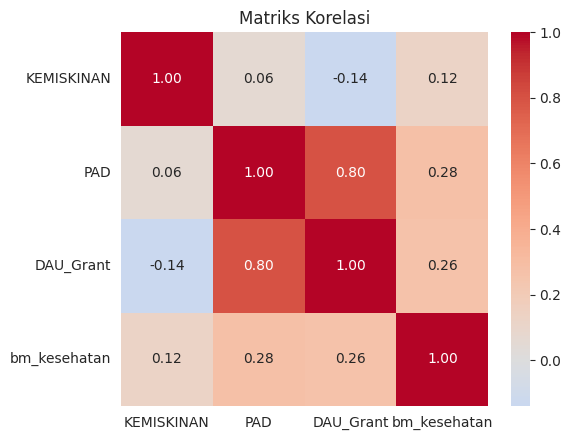

In [9]:
kor = data[[Y_COL] + X_COLS].corr().round(2)
display(kor)
plt.figure(figsize=(6, 4.5))
sns.heatmap(kor, annot=True, cmap="coolwarm", center=0, fmt=".2f")
plt.title("Matriks Korelasi"); plt.tight_layout(); plt.show()

# Model 1 (regresi berganda / Pooled OLS) dan Model 2 (Fixed Effect)

In [10]:
rumus = f"{Y_COL} ~ " + " + ".join(X_COLS)
m1 = smf.ols(rumus, data=data).fit()
m2 = smf.ols(rumus + " + C(Kota)", data=data).fit()

print("=== MODEL 1: Pooled OLS ===")
print(m1.summary())
print("\n=== MODEL 2: Fixed Effect (dummy kota) ===")
print(m2.summary())

pd.DataFrame({
    "R2":     [m1.rsquared, m2.rsquared],
    "Adj R2": [m1.rsquared_adj, m2.rsquared_adj],
    "AIC":    [m1.aic, m2.aic],
    "BIC":    [m1.bic, m2.bic],
    "F p-value": [m1.f_pvalue, m2.f_pvalue],
}, index=["Model 1 (Pooled)", "Model 2 (Fixed Effect)"]).round(4)

=== MODEL 1: Pooled OLS ===
                            OLS Regression Results                            
Dep. Variable:             KEMISKINAN   R-squared:                       0.124
Model:                            OLS   Adj. R-squared:                  0.034
Method:                 Least Squares   F-statistic:                     1.372
Date:                Tue, 13 Oct 2026   Prob (F-statistic):              0.271
Time:                        05:29:59   Log-Likelihood:                -94.726
No. Observations:                  33   AIC:                             197.5
Df Residuals:                      29   BIC:                             203.4
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
Intercept       11.9

,R2,Adj R2,AIC,BIC,F p-value
Model 1 (Pooled),0.1243,0.0337,197.4523,203.4384,0.2710
Model 2 (Fixed Effect),0.2246,0.0810,197.4394,206.4184,0.2039


## Tabel koefisien Model 1 (uji t)

In [11]:
tab = pd.DataFrame({"Koefisien": m1.params, "Std. Error": m1.bse, "t-hitung": m1.tvalues, "p-value": m1.pvalues})
tab["Keputusan (5%)"] = np.where(tab["p-value"] < ALPHA, "Signifikan", "Tidak signifikan")
tab.round(4)

,Koefisien,Std. Error,t-hitung,p-value,Keputusan (5%)
Intercept,11.9835,2.7921,4.2919,0.0002,Signifikan
PAD,0.0245,0.0155,1.5854,0.1237,Tidak signifikan
DAU_Grant,-0.0349,0.0184,-1.8957,0.0680,Tidak signifikan
bm_kesehatan,0.0087,0.0115,0.7567,0.4553,Tidak signifikan


# Cek multikolinearitas (VIF)

In [12]:
X = sm.add_constant(data[X_COLS])
vif = pd.DataFrame({"Variabel": X.columns,
                    "VIF": [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]})
vif = vif[vif["Variabel"] != "const"]
vif["Keterangan"] = np.where(vif["VIF"] < 10, "Aman (< 10)", "Multikolinearitas")
vif.round(3)

,Variabel,VIF,Keterangan
1,PAD,2.811,Aman (< 10)
2,DAU_Grant,2.783,Aman (< 10)
3,bm_kesehatan,1.087,Aman (< 10)


# Uji asumsi klasik (Model 1)

In [13]:
res = m1.resid
sh = stats.shapiro(res)
bp = het_breuschpagan(res, m1.model.exog)
dw = durbin_watson(res)
print(f"Normalitas (Shapiro-Wilk)     : p = {sh.pvalue:.4f} -> {'Normal' if sh.pvalue > ALPHA else 'Tidak normal'}")
print(f"Heteroskedastisitas (Breusch-Pagan): p = {bp[1]:.4f} -> {'Homoskedastis' if bp[1] > ALPHA else 'Heteroskedastis'}")
print(f"Autokorelasi (Durbin-Watson)  : {dw:.3f}  (sekitar 2 = tidak ada autokorelasi)")

Normalitas (Shapiro-Wilk)     : p = 0.0817 -> Normal
Heteroskedastisitas (Breusch-Pagan): p = 0.2140 -> Homoskedastis
Autokorelasi (Durbin-Watson)  : 1.835  (sekitar 2 = tidak ada autokorelasi)


# Grafik 3D Regresi (Plotly – bisa diputar & di-zoom)
- **Titik merah** = data aktual (1 titik = 1 kota pada 1 tahun; arahkan kursor untuk melihat kota & tahun).
- **Bidang berwarna** = bidang regresi dari model dengan 2 variabel X yang ditampilkan.
- Persamaan dan R² ada di judul grafik. Tombol **Putar / Stop** menggerakkan grafik otomatis.

In [14]:
def grafik_3d(v1, v2, y_col=Y_COL):
    x1, x2, y = data[v1], data[v2], data[y_col]
    model3d = smf.ols(f"{y_col} ~ {v1} + {v2}", data=data).fit()

    X1g, X2g = np.meshgrid(np.linspace(x1.min(), x1.max(), 30),
                           np.linspace(x2.min(), x2.max(), 30))
    Yg = model3d.params["Intercept"] + model3d.params[v1] * X1g + model3d.params[v2] * X2g

    fig = go.Figure()
    fig.add_trace(go.Scatter3d(
        x=x1, y=x2, z=y, mode="markers",
        marker=dict(size=6, color="red", opacity=0.9), name="Data Aktual",
        text=[f"Kota: {k}, Tahun: {t}" for k, t in zip(data["Kota"], data["Tahun"])],
        hovertemplate="<b>%{text}</b><br>" + v1 + ": %{x}<br>" + v2 + ": %{y}<br>" + y_col + ": %{z}<extra></extra>"))
    fig.add_trace(go.Surface(x=X1g, y=X2g, z=Yg, opacity=0.6, colorscale="Viridis",
                             name="Bidang Regresi", showscale=False, hoverinfo="skip"))

    persamaan = (f"Y = {model3d.params['Intercept']:.3f} "
                 f"+ ({model3d.params[v1]:.4f})X1 + ({model3d.params[v2]:.4f})X2")
    kota_txt = ", ".join(k.replace("Kota ", "") for k in data["Kota"].unique()) if data["Kota"].nunique() <= 4 else f"{data['Kota'].nunique()} KOTA"

    # animasi putar otomatis
    kam = lambda t: {"eye": {"x": 2.0*np.cos(t), "y": 2.0*np.sin(t), "z": 0.9}}
    fig.frames = [go.Frame(layout={"scene": {"camera": kam(t)}}) for t in np.linspace(0, 2*np.pi, 48)]
    tombol = [{"type": "buttons", "direction": "left", "x": 0.0, "y": 1.0, "showactive": False, "buttons": [
        {"label": "▶ Putar", "method": "animate",
         "args": [None, {"frame": {"duration": 70, "redraw": True}, "fromcurrent": True, "transition": {"duration": 0}}]},
        {"label": "⏸ Stop", "method": "animate",
         "args": [[None], {"frame": {"duration": 0, "redraw": False}, "mode": "immediate", "transition": {"duration": 0}}]}]}]

    fig.update_layout(
        title={"text": f"REGRESI LINEAR BERGANDA 3D – {kota_txt}<br><sup>{persamaan} | R² = {model3d.rsquared:.3f}</sup>", "x": 0.5},
        scene={"xaxis": {"title": f"{v1} (X₁)"}, "yaxis": {"title": f"{v2} (X₂)"}, "zaxis": {"title": f"{y_col} (Y)"},
               "camera": {"eye": {"x": 1.6, "y": -1.6, "z": 1.0}}},
        updatemenus=tombol, width=1000, height=750, margin={"l": 0, "r": 0, "b": 0, "t": 100})
    return fig, model3d

# dua X paling signifikan (|t| terbesar) pada Model 1
urut = m1.tvalues[X_COLS].abs().sort_values(ascending=False).index.tolist()
v1, v2 = urut[0], urut[1]
fig, model3d = grafik_3d(v1, v2)
print(model3d.summary())
fig.show()
fig.write_html("grafik_regresi_3d.html")

                            OLS Regression Results                            
Dep. Variable:             KEMISKINAN   R-squared:                       0.107
Model:                            OLS   Adj. R-squared:                  0.047
Method:                 Least Squares   F-statistic:                     1.797
Date:                Tue, 13 Oct 2026   Prob (F-statistic):              0.183
Time:                        05:29:59   Log-Likelihood:                -95.049
No. Observations:                  33   AIC:                             196.1
Df Residuals:                      30   BIC:                             200.6
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     12.8832      2.508      5.136      0.0

## 3D untuk pasangan X lainnya

In [15]:
for a, b in combinations(X_COLS, 2):
    if (a, b) == (v1, v2) or (b, a) == (v1, v2):
        continue
    f, _ = grafik_3d(a, b)
    f.show()
    f.write_html(f"grafik_regresi_3d_{a}_{b}.html")

# Grafik aktual vs prediksi

In [16]:
y = data[Y_COL]
lim = [min(y.min(), m2.fittedvalues.min()), max(y.max(), m2.fittedvalues.max())]
fa = go.Figure()
fa.add_trace(go.Scatter(x=y, y=m2.fittedvalues, mode="markers", name="Data (Model 2)",
                        marker=dict(size=8), text=data["Kota"] + " " + data["Tahun"].astype(str)))
fa.add_trace(go.Scatter(x=lim, y=lim, mode="lines", name="Garis ideal", line=dict(color="red", dash="dash")))
fa.update_layout(title=f"Aktual vs Prediksi (Model 2, R² = {m2.rsquared:.3f})",
                 xaxis_title="Aktual", yaxis_title="Prediksi", width=650, height=550)
fa.show()

# Kesimpulan (otomatis dari hasil di atas)

In [18]:
sig = [c for c in X_COLS if m1.pvalues[c] < ALPHA]
efek = [c for c in m2.pvalues.index if c.startswith("C(Kota)") and m2.pvalues[c] < ALPHA]
ref = sorted(data["Kota"].unique())[0]

print(f"1. Variabel signifikan: " + (
    f"{', '.join(sig)} berpengaruh signifikan terhadap {Y_COL} pada taraf nyata 5% (p < 0,05)." if sig else
    f"Tidak ada variabel bebas ({', '.join(X_COLS)}) yang berpengaruh signifikan secara statistik terhadap {Y_COL} pada taraf nyata 5% (p > 0,05)."))
for c in X_COLS:
    print(f"   - {c}: koef = {m1.params[c]:.4f}, p = {m1.pvalues[c]:.4f}")

print(f"\n2. Uji F simultan (Model 1): p = {m1.f_pvalue:.4f} -> " +
      ("variabel X secara simultan berpengaruh signifikan." if m1.f_pvalue < ALPHA else "variabel X secara simultan tidak berpengaruh signifikan."))

print(f"\n3. Nilai R-squared: Pooled OLS = {m1.rsquared:.4f} ({m1.rsquared*100:.2f}%), Fixed Effect = {m2.rsquared:.4f} ({m2.rsquared*100:.2f}%). "
      + ("Kemampuan variabel independen menjelaskan " + Y_COL + " tergolong rendah; sebagian besar dipengaruhi faktor lain di luar model." if m1.rsquared < 0.3 else
         "Variabel independen cukup mampu menjelaskan " + Y_COL + "."))

print(f"\n4. Multikolinearitas (VIF): " + (
    f"Aman. Seluruh VIF berada di kisaran {vif.VIF.min():.3f} hingga {vif.VIF.max():.3f} (di bawah 10)." if (vif.VIF < 10).all() else
    "Terdapat multikolinearitas (VIF >= 10) pada: " + ", ".join(vif.loc[vif.VIF >= 10, "Variabel"]) + "."))

lebih = "Fixed Effect" if m2.aic < m1.aic else "Pooled OLS"
print(f"\n5. Perbandingan model: AIC Pooled = {m1.aic:.1f}, AIC Fixed Effect = {m2.aic:.1f} -> model {lebih} lebih baik berdasarkan AIC."
      + (f" Efek kota yang signifikan: {', '.join(e.replace('C(Kota)[T.', '').rstrip(']') for e in efek)} (dibanding {ref})." if efek else " Tidak ada efek kota yang signifikan."))

1. Variabel signifikan: Tidak ada variabel bebas (PAD, DAU_Grant, bm_kesehatan) yang berpengaruh signifikan secara statistik terhadap KEMISKINAN pada taraf nyata 5% (p > 0,05).
   - PAD: koef = 0.0245, p = 0.1237
   - DAU_Grant: koef = -0.0349, p = 0.0680
   - bm_kesehatan: koef = 0.0087, p = 0.4553

2. Uji F simultan (Model 1): p = 0.2710 -> variabel X secara simultan tidak berpengaruh signifikan.

3. Nilai R-squared: Pooled OLS = 0.1243 (12.43%), Fixed Effect = 0.2246 (22.46%). Kemampuan variabel independen menjelaskan KEMISKINAN tergolong rendah; sebagian besar dipengaruhi faktor lain di luar model.

4. Multikolinearitas (VIF): Aman. Seluruh VIF berada di kisaran 1.087 hingga 2.811 (di bawah 10).

5. Perbandingan model: AIC Pooled = 197.5, AIC Fixed Effect = 197.4 -> model Fixed Effect lebih baik berdasarkan AIC. Tidak ada efek kota yang signifikan.
